# MedPlain – klasszikus és mélytanulásos modellek összehasonlítása

Minden modell **ugyanazon a teszthalmazon** van mérve: 3048 mondat, 150 cikk, cikkenkénti GroupShuffleSplit, random_state=42.
- **Klasszikus modellek** (TF-IDF + NB / LogReg / SVM / RF): a `models/` mappában mentett pipeline-ok, itt újra kiértékelve.
- **DL modellek:** mindenki a saját notebookja végén a `dp.save_result(...)` hívással ment egy `results/<kulcs>.json` fájlt. Ez a notebook ezeket olvassa be.

Az ujjlenyomat-ellenőrzés kiszűri, ha valaki más teszthalmazon mért (pl. eltérő `dl_prep.py` verzióval).

| # | Modell | kulcs (`results/<kulcs>.json`) |
|---|---|---|
| 1 | Embedding + GlobalAveragePooling1D | `baseline` |
| 2 | Embedding + Bidirectional(LSTM) | `bilstm` |
| 3 | Embedding + Conv1D + GlobalMaxPooling1D | `cnn` |
| 4 | Embedding + Bidirectional(GRU) | `bigru` |

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import dl_prep as dp
from train_models import prepare

EXPECTED_DL = {"baseline": "1. Embedding + GAP", "bilstm": "2. BiLSTM", "cnn": "3. Conv1D", "bigru": "4. BiGRU"}

I0000 00:00:1794300680.657296   23056 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794300680.657876   23056 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1794300681.731423   23056 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794300681.731788   23056 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Klasszikus modellek a közös teszthalmazon

In [2]:
_, test_df, _ = prepare()
test_df = test_df.reset_index(drop=True)
fingerprint = dp.test_fingerprint(test_df)
y_test = test_df.label.to_numpy()
print(f"Teszthalmaz: {len(test_df)} mondat, {test_df.article.nunique()} cikk, ujjlenyomat: {fingerprint}")

manifest = json.loads((dp.ROOT / "models" / "manifest.json").read_text(encoding="utf-8"))
rows = []
for m in manifest:
    pred = joblib.load(dp.ROOT / "models" / m["artifact"]).predict(test_df.text)
    rows.append({"Modell": m["name"], "Típus": "klasszikus (TF-IDF)",
                 "Accuracy": accuracy_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "cm": confusion_matrix(y_test, pred, labels=[0, 1]),
                 "Paraméterek": None, "Tanítás (s)": None, "Epochok": None})

Teszthalmaz: 3048 mondat, 150 cikk, ujjlenyomat: cefa7c9f57300365


## DL modellek beolvasása

In [3]:
histories = {}
loaded = set()
for r in dp.load_results():
    if r["test_fingerprint"] != fingerprint:
        print(f"⚠ {r['key']}: MÁS teszthalmazon mérve ({r['test_fingerprint']}), kihagyva – frissítsd a dl_prep.py-t és futtasd újra.")
        continue
    loaded.add(r["key"])
    rows.append({"Modell": r["name"], "Típus": "DL" + (" (GPU)" if r["setup"].get("gpu") else " (CPU)"),
                 "Accuracy": r["accuracy"], "F1": r["f1"], "cm": np.array(r["confusion_matrix"]),
                 "Paraméterek": r["params"], "Tanítás (s)": r["train_seconds"],
                 "Epochok": f"{r['epochs_run']} (legjobb {r['best_epoch']})"})
    histories[r["name"]] = r["history"]
missing = [f"{v} ({k}.json)" for k, v in EXPECTED_DL.items() if k not in loaded]
print("Beolvasott DL eredmények:", sorted(loaded))
if missing:
    print("Még hiányzik:", ", ".join(missing))

Beolvasott DL eredmények: ['baseline']
Még hiányzik: 2. BiLSTM (bilstm.json), 3. Conv1D (cnn.json), 4. BiGRU (bigru.json)


## Összehasonlító tábla

In [4]:
table = pd.DataFrame(rows).sort_values("Accuracy", ascending=False).reset_index(drop=True)
display(table.drop(columns="cm").style.format({
    "Accuracy": "{:.2%}", "F1": "{:.2%}", "Paraméterek": lambda v: "–" if pd.isna(v) else f"{int(v):,}".replace(",", " "),
    "Tanítás (s)": lambda v: "–" if pd.isna(v) else f"{v:.1f}", "Epochok": lambda v: "–" if pd.isna(v) else v}).hide(axis="index"))

Modell,Típus,Accuracy,F1,Paraméterek,Tanítás (s),Epochok
Lineáris SVM,klasszikus (TF-IDF),81.43%,81.85%,–,–,–
Logisztikus regresszió,klasszikus (TF-IDF),81.33%,81.75%,–,–,–
Naiv Bayes,klasszikus (TF-IDF),81.10%,81.37%,–,–,–
Embedding + GAP (baseline),DL (CPU),80.71%,80.44%,1 195 929,6.9,5 (legjobb 2)
Random Forest,klasszikus (TF-IDF),75.95%,74.66%,–,–,–


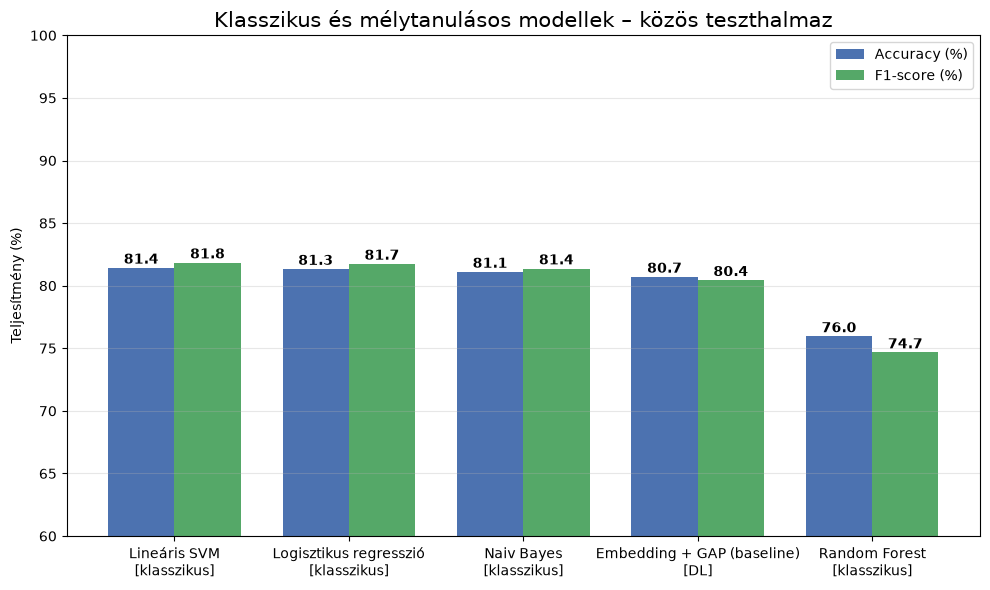

In [5]:
fig, ax = plt.subplots(figsize=(max(10, 1.5 * len(table)), 6))
x = np.arange(len(table)); w = 0.38
b1 = ax.bar(x - w/2, table.Accuracy * 100, w, label="Accuracy (%)", color="#4C72B0")
b2 = ax.bar(x + w/2, table.F1 * 100, w, label="F1-score (%)", color="#55A868")
for bars in (b1, b2):
    for b in bars:
        ax.annotate(f"{b.get_height():.1f}", (b.get_x() + b.get_width()/2, b.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10, fontweight="bold")
labels = [f"{m}\n[{'DL' if t.startswith('DL') else 'klasszikus'}]" for m, t in zip(table.Modell, table.Típus)]
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=10)
lo = max(0, np.floor(min(table.Accuracy.min(), table.F1.min()) * 10) * 10 - 10)
ax.set_ylim(lo, 100); ax.set_ylabel("Teljesítmény (%)")
ax.set_title("Klasszikus és mélytanulásos modellek – közös teszthalmaz", fontsize=15)
ax.legend(loc="upper right"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## Konfúziós mátrixok

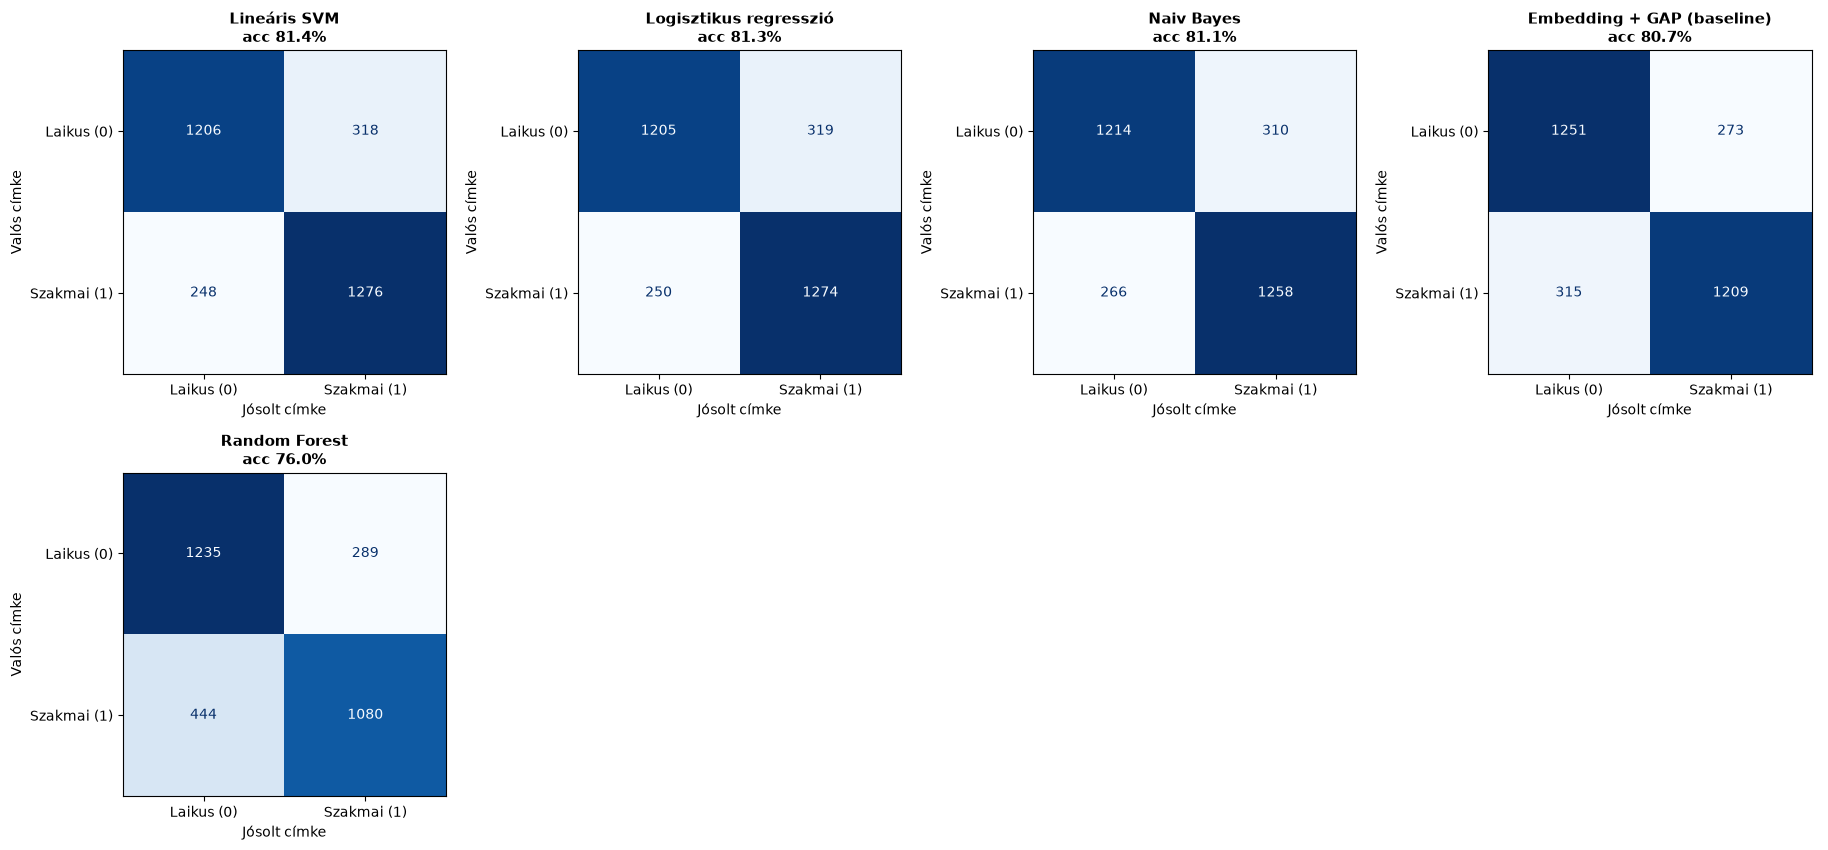

In [6]:
n = len(table); cols = 4; rws = int(np.ceil(n / cols))
fig, axes = plt.subplots(rws, cols, figsize=(4.6 * cols, 4.3 * rws))
axes = np.atleast_1d(axes).ravel()
for ax, (_, r) in zip(axes, table.iterrows()):
    dp.plot_confusion(r.cm, f"{r.Modell}\nacc {r.Accuracy:.1%}", ax=ax)
    ax.title.set_fontsize(11)
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## DL tanulási görbék (validációs halmaz)

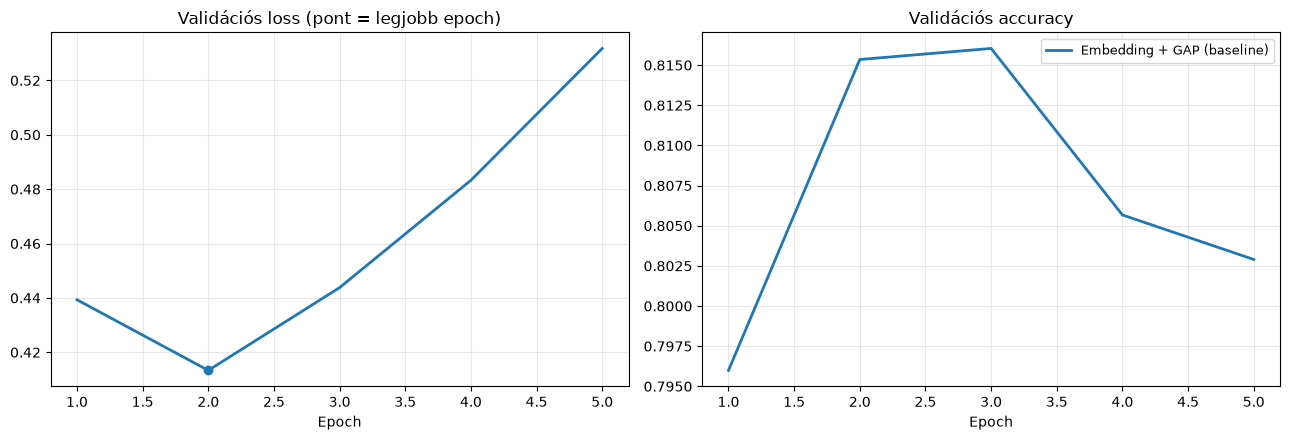

In [7]:
if histories:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for name, h in histories.items():
        ep = np.arange(1, len(h["val_loss"]) + 1)
        line, = axes[0].plot(ep, h["val_loss"], lw=2, label=name)
        best = int(np.argmin(h["val_loss"]))
        axes[0].plot(best + 1, h["val_loss"][best], "o", color=line.get_color())
        axes[1].plot(ep, h["val_accuracy"], lw=2, color=line.get_color(), label=name)
    axes[0].set_title("Validációs loss (pont = legjobb epoch)"); axes[1].set_title("Validációs accuracy")
    for ax in axes:
        ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
    axes[1].legend(fontsize=9)
    plt.tight_layout(); plt.show()

## Megjegyzések az értelmezéshez
- **Zaj:** a baseline DL modell 3 seeddel ±1 százalékpont szórást mutat a teszten (lásd `dl_1_baseline.ipynb`). Az ennél kisebb különbségek nem jelentenek valódi rangsort.
- **Klasszikus vs. DL tanítóhalmaz:** a klasszikus modellek a teljes train halmazon tanultak, a DL modellek ennek 88%-án, mert 12% a validációra (EarlyStopping) ment el. A teszthalmaz mindkét esetben azonos.
- **Összegző notebook vs. ez:** a régi `modell osszehasonlitas (Osszegzes).ipynb` sima `train_test_split`-et használt, ott ugyanannak a cikknek a mondatai a train és a test halmazba is kerülhettek. Az itteni számok ezért a szigorúbb, cikkenkénti felosztásra vonatkoznak.